# EDA dữ liệu truy cập logistics — Task 1

Notebook phân tích **toàn bộ** `data/raw_logs.txt` cùng bảng `data/ip_geolocation.csv`, phục vụ kiểm tra đầu vào và giải thích pipeline RDD. Các kết quả được tính trực tiếp từ file, không lấy số liệu cố định trong README.

**Câu hỏi phân tích:** Dữ liệu có bao nhiêu dòng và request? Lỗi định dạng nằm ở đâu? Phân bố quốc gia, IP, endpoint và HTTP status ra sao? Độ trễ và kích thước phản hồi có bất thường không? Dataset có đủ tính thực tế để kết luận về hoạt động logistics không?

**Đơn vị quan sát:** một dòng vật lý có thể chứa nhiều request phân cách bằng `;`. Dòng hỏng, HTTP 4xx/5xx và IP không tra được là ba vấn đề khác nhau. Mọi tỷ lệ bên dưới ghi rõ mẫu số.

**Cách chạy:** chọn Python kernel có các thư viện trong `requirements-eda.txt`, sau đó **Restart Kernel → Run All**. Notebook dùng pandas để khảo sát file khoảng 114 MiB, không thay thế bài thực hành Spark. Nên có khoảng 2–3 GB RAM trống. Không sửa dữ liệu nguồn; các cell vẽ biểu đồ lưu PNG vào `data/output/eda/`.

**Ghi chú thuyết trình:** Mỗi cell code có phần mục đích phía trên và phần đọc kết quả phía dưới. Các nhận xét số liệu bên dưới được viết theo output hiện có; cần cập nhật nếu sinh lại dữ liệu hoặc chạy trên file khác.

## Cell 1 — Chuẩn bị môi trường

Nạp thư viện, xác định đường dẫn dữ liệu và thiết lập cách hiển thị bảng, biểu đồ. Không thay đổi file log gốc.

In [ ]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from urllib.parse import urlsplit, parse_qs
import csv, hashlib, ipaddress, platform, re, sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data' / 'raw_logs.txt').is_file()), None)
LOG_PATH = ROOT / 'data/raw_logs.txt'
LOOKUP_PATH = ROOT / 'data/ip_geolocation.csv'
OUT = ROOT / 'data/output/eda'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

Python: 3.12.4 | pandas: 2.3.3 | numpy: 1.26.4 | matplotlib: 3.10.8
Project: D:\BigData\spark-core-apis


Môi trường đang dùng Python **3.12.4**, pandas **2.3.3**, NumPy **1.26.4** và matplotlib **3.10.8**. Đường dẫn đã trỏ đúng tới dự án nên các cell sau có thể đọc log và bảng tra quốc gia.

Bước này chỉ chuẩn bị công cụ, chưa đưa ra nhận xét về dữ liệu. `SEED = 42` giúp lần lấy mẫu để vẽ scatter có thể lặp lại; không làm thay đổi file log đã sinh.

## Cell 2 — Kiểm tra file đầu vào

Xem dung lượng, mã SHA-256 để nhận diện phiên bản dữ liệu và 5 dòng log đầu tiên.

In [2]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

manifest = pd.DataFrame([{
    'file': p.name, 'bytes': p.stat().st_size,
    'MiB': p.stat().st_size / 1024**2, 'sha256': file_sha256(p)
} for p in [LOG_PATH, LOOKUP_PATH]])
display(manifest)
with LOG_PATH.open(encoding='utf-8') as f:
    for _, line in zip(range(5), f):
        print(line.rstrip())

139.130.0.21 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-39528 HTTP/1.1" 200 2557 100ms
CORRUPTED_PACKET_HEADER_0xD50_ERR
198.51.100.39 - - [16/Sep/2026:10:00:00 +0000] "POST /api/v1/dispatch/schedule?order_id=ORD-58836 HTTP/1.1" 200 3004 103ms
139.130.0.56 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-47922 HTTP/1.1" 200 4020 87ms
200.160.0.73 - - [16/Sep/2026:10:00:00 +0000] "GET /api/v1/shipments/track?tx_id=TXN-15426 HTTP/1.1" 200 2868 36ms


,file,bytes,MiB,sha256
0,raw_logs.txt,119703440,114.158,182c763612c63f01905c40a8e37e0a7515187db1c9a235...
1,ip_geolocation.csv,466,0.000,110b2327c8c17a1bd1edf063089ea0279abb334ffa32b2...


File `raw_logs.txt` có dung lượng **114,16 MiB**; bảng tra quốc gia chỉ có **466 bytes**. Điều này cho thấy đầu vào gồm một tập log lớn hơn nhiều so với bảng tra nhỏ, phù hợp với ý tưởng broadcast bảng tra trong Task 1.

Trong 5 dòng đầu đã xuất hiện `CORRUPTED_PACKET_HEADER...`, xác nhận log chứa bản ghi lỗi được chủ động sinh. Năm dòng chỉ giúp xem định dạng, chưa đủ để kết luận tỷ lệ lỗi; tỷ lệ chính xác được đếm trên toàn file ở cell tiếp theo. SHA-256 là mã nhận diện snapshot: khi sinh lại data, cần đối chiếu mã này trước khi so sánh kết quả.

## Cell 3 — Đọc log và thống kê chất lượng

Tách các request ghép bằng dấu `;`, đọc các trường và đếm entry hợp lệ hoặc sai định dạng. Entry lỗi được thống kê riêng; file nguồn giữ nguyên.

In [3]:
FULL_PATTERN = re.compile(
    r'^(?P<ip>\S+) - - \[(?P<timestamp>[^\]]+)\] '
    r'"(?P<method>\S+) (?P<url>\S+) HTTP/(?P<protocol>\S+)" '
    r'(?P<status>\d{3}) (?P<response_bytes>\d+) (?P<latency_ms>\d+)ms$')
TASK_PATTERN = re.compile(r'^(\S+) - - \[.*?\] "\S+ \S+ \S+" (\d{3})')
audit = Counter()
errors, rows = [], []
error_counts = Counter()
ip_cache, time_cache = {}, {}
def record_error(kind, line_no, entry):
    error_counts[kind] += 1
    if sum(e['reason'] == kind for e in errors) < 10:
        errors.append({'line_no': line_no, 'reason': kind, 'raw': entry[:250]})

with LOG_PATH.open(encoding='utf-8') as source:
    for line_no, line in enumerate(source, 1):
        audit['physical_lines'] += 1
        parts = [p.strip() for p in line.strip().split(';') if p.strip()]
        audit['blank_lines'] += int(not parts)
        audit['compound_lines'] += int(len(parts) > 1)
        audit['entries'] += len(parts)
        line_has_error = False
        for position, entry in enumerate(parts, 1):
            tm = TASK_PATTERN.match(entry)
            audit['task_regex_valid'] += int(tm is not None)
            audit['task_status_200'] += int(tm is not None and tm.group(2) == '200')
            match = FULL_PATTERN.fullmatch(entry)
            if not match:
                record_error('invalid_format', line_no, entry)
                line_has_error = True
                continue
            d = match.groupdict()
            try:
                if d['ip'] not in ip_cache:
                    ip_cache[d['ip']] = int(ipaddress.IPv4Address(d['ip']))
                if d['timestamp'] not in time_cache:
                    time_cache[d['timestamp']] = datetime.strptime(d['timestamp'], '%d/%b/%Y:%H:%M:%S %z')
                status = int(d['status'])
                if not 100 <= status <= 599:
                    raise ValueError('invalid status')
            except ValueError:
                record_error('invalid_ip_time_or_status', line_no, entry)
                line_has_error = True
                continue
            rows.append((line_no, position, len(parts), d['ip'], ip_cache[d['ip']],
                         d['timestamp'], d['method'], d['url'], d['protocol'], status,
                         int(d['response_bytes']), int(d['latency_ms'])))
        audit['lines_with_invalid_entries'] += int(line_has_error)

df = pd.DataFrame.from_records(rows, columns=[
    'line_no', 'entry_position', 'entries_in_line', 'ip', 'ip_int', 'timestamp',
    'method', 'url', 'protocol', 'status', 'response_bytes', 'latency_ms'])
del rows
if df.empty:
    raise ValueError('Không có request hợp lệ để EDA; xem parser và dữ liệu nguồn.')
df['timestamp'] = pd.to_datetime(df['timestamp'].map(time_cache), utc=True)
for c in ['line_no', 'entry_position', 'entries_in_line', 'status', 'response_bytes', 'latency_ms']:
    df[c] = pd.to_numeric(df[c], downcast='unsigned')
for c in ['ip', 'method', 'protocol']:
    df[c] = df[c].astype('category')
invalid_entries = sum(error_counts.values())
assert audit['entries'] == len(df) + invalid_entries
quality = pd.DataFrame([
    ('Physical lines', audit['physical_lines']), ('Blank lines', audit['blank_lines']),
    ('Compound lines', audit['compound_lines']), ('Expanded entries', audit['entries']),
    ('Valid full records', len(df)), ('Invalid entries', invalid_entries),
    ('Lines containing invalid entries', audit['lines_with_invalid_entries']),
    ('Task regex accepted', audit['task_regex_valid']), ('Task HTTP 200', audit['task_status_200'])
], columns=['metric', 'count'])
display(quality)
display(pd.DataFrame(errors))
display(df.head())
print(f"Dòng chứa lỗi / dòng vật lý: {audit['lines_with_invalid_entries'] / audit['physical_lines']:.2%}")
print(f"Entry lỗi / entry sau tách: {invalid_entries / audit['entries']:.2%}")

Dòng chứa lỗi / dòng vật lý: 1.39%
Entry lỗi / entry sau tách: 1.34%


,metric,count
0,Physical lines,1000000
1,Blank lines,0
2,Compound lines,34403
3,Expanded entries,1034403
4,Valid full records,1020495
5,Invalid entries,13908
6,Lines containing invalid entries,13908
7,Task regex accepted,1020495
8,Task HTTP 200,981101


,line_no,reason,raw
0,2,invalid_format,CORRUPTED_PACKET_HEADER_0xD50_ERR
1,51,invalid_format,CORRUPTED_PACKET_HEADER_0x2284_ERR
2,87,invalid_format,CORRUPTED_PACKET_HEADER_0x2367_ERR
3,92,invalid_format,CORRUPTED_PACKET_HEADER_0x17A4_ERR
4,171,invalid_format,CORRUPTED_PACKET_HEADER_0x1E4E_ERR
5,218,invalid_format,CORRUPTED_PACKET_HEADER_0xA4F_ERR
6,228,invalid_format,CORRUPTED_PACKET_HEADER_0x1CD9_ERR
7,476,invalid_format,CORRUPTED_PACKET_HEADER_0x570_ERR
8,631,invalid_format,CORRUPTED_PACKET_HEADER_0x1774_ERR
9,635,invalid_format,CORRUPTED_PACKET_HEADER_0x174E_ERR


,line_no,entry_position,entries_in_line,ip,ip_int,timestamp,method,url,protocol,status,response_bytes,latency_ms
0,1,1,1,139.130.0.21,2340552725,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-39528,1.1,200,2557,100
1,3,1,1,198.51.100.39,3325256743,2026-09-16 10:00:00+00:00,POST,/api/v1/dispatch/schedule?order_id=ORD-58836,1.1,200,3004,103
2,4,1,1,139.130.0.56,2340552760,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-47922,1.1,200,4020,87
3,5,1,1,200.160.0.73,3365929033,2026-09-16 10:00:00+00:00,GET,/api/v1/shipments/track?tx_id=TXN-15426,1.1,200,2868,36
4,6,1,1,151.101.0.105,2539978857,2026-09-16 10:00:00+00:00,GET,/api/v1/rates/calculator,1.1,200,1833,56


File có **1.000.000 dòng vật lý**, không có dòng rỗng. Trong đó, **34.403 dòng chứa hai request**, nên sau khi tách dấu `;` có **1.034.403 entry**. Đây là lý do số entry lớn hơn số dòng đầu vào và cũng minh họa nhu cầu dùng `flatMap` trong Task 1.

Có **13.908 entry sai định dạng**, còn **1.020.495 request hợp lệ**. Tỷ lệ lỗi là **1,39% trên số dòng gốc** và **1,34% trên số entry sau tách**; hai tỷ lệ khác nhau do mẫu số khác nhau. Các ví dụ lỗi có dạng `CORRUPTED_PACKET_HEADER...`, phù hợp với cách generator tạo dữ liệu hỏng.

Trong các request hợp lệ, **981.101 request có HTTP 200**. Hai parser chấp nhận cùng số request trên snapshot này. Các entry lỗi chỉ được thống kê riêng, không bị xóa khỏi file nguồn; Task 1 vẫn có thể dùng chúng để kiểm tra xử lý log hỏng.

## Cell 4 — Kiểm tra bảng tra quốc gia

Kiểm tra 15 quy tắc CIDR, tìm dải IP trùng/chồng lấn và tra quốc gia cho từng IP để phục vụ EDA.

In [4]:
lookup = pd.read_csv(LOOKUP_PATH)
assert {'cidr_block', 'country_code', 'country_name'} <= set(lookup.columns)
assert not lookup.isna().any().any(), 'Lookup có giá trị thiếu'
networks = [ipaddress.IPv4Network(s) for s in lookup['cidr_block']]
overlaps = [(str(a), str(b)) for i, a in enumerate(networks)
            for b in networks[i+1:] if a.overlaps(b)]
display(lookup)
print('Rules:', len(lookup), '| Countries:', lookup.country_code.nunique(),
      '| Duplicate CIDRs:', lookup.cidr_block.duplicated().sum())
print('Overlapping rules:', overlaps)

def locate(ip):
    n = int(ipaddress.IPv4Address(ip))
    for net, row in zip(networks, lookup.itertuples(index=False)):
        if n & int(net.netmask) == int(net.network_address):
            return row.country_code, row.country_name, row.cidr_block
    return 'Unknown', 'Unknown', 'Unknown'

locations = {ip: locate(ip) for ip in df['ip'].cat.categories}
for idx, col in enumerate(['country_code', 'country', 'cidr_block']):
    df[col] = df['ip'].astype('object').map({k: v[idx] for k, v in locations.items()}).astype('category')
print(f"Unknown requests: {(df.country == 'Unknown').sum():,} / {len(df):,}")

Rules: 15 | Countries: 14 | Duplicate CIDRs: 0
Overlapping rules: []
Unknown requests: 0 / 1,020,495


,cidr_block,country_code,country_name
0,103.21.240.0/20,VN,Vietnam
1,103.7.32.0/19,SG,Singapore
2,192.168.0.0/16,US,United States
3,198.51.100.0/24,US,United States
4,203.0.112.0/20,JP,Japan
5,185.220.96.0/19,DE,Germany
6,51.15.0.0/16,FR,France
7,151.101.0.0/16,GB,United Kingdom
8,210.140.0.0/16,KR,South Korea
9,139.130.0.0/16,AU,Australia


Bảng tra chứa **15 dải IP ứng với 14 quốc gia** vì US được gán hai dải. Không có CIDR trùng hoặc chồng lấn, nên trong bảng hiện tại không phát sinh trường hợp một IP khớp nhiều quy tắc.

Cả **1.020.495 request hợp lệ** đều tra được quốc gia, tức tỷ lệ bao phủ là **100%** và không có `Unknown`. Kết quả phù hợp với việc generator sinh IP từ chính các dải trong bảng tra. Điều này xác nhận sự nhất quán của dữ liệu mô phỏng, không chứng minh bảng có thể định vị chính xác IP ngoài thực tế.

## Cell 5 — Kiểm tra giá trị thiếu và trùng

Xem kiểu dữ liệu, số giá trị thiếu, số giá trị khác nhau, bộ nhớ và số request trùng. Không xóa bản ghi trùng.

In [5]:
schema = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                       'unique': df.nunique(), 'memory_MiB': df.memory_usage(deep=True).drop('Index') / 1024**2})
display(schema)
duplicate_fields = ['ip', 'timestamp', 'method', 'url', 'protocol', 'status', 'response_bytes', 'latency_ms']
duplicates = int(df.duplicated(duplicate_fields).sum())
print(f'Duplicate records beyond first occurrence: {duplicates:,} ({duplicates / len(df):.4%})')
print(f'DataFrame memory: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MiB')

Duplicate records beyond first occurrence: 3 (0.0003%)
DataFrame memory: 118.7 MiB


,dtype,missing,unique,memory_MiB
line_no,uint32,0,986092,3.893
entry_position,uint8,0,2,0.973
entries_in_line,uint8,0,2,0.973
ip,category,0,3735,2.292
ip_int,int64,0,3735,7.786
timestamp,"datetime64[ns, UTC]",0,1,7.786
method,category,0,2,0.973
url,object,0,342150,85.298
protocol,category,0,1,0.973
status,uint16,0,4,1.946


Bảng sau khi parse không có giá trị thiếu, có **3.735 IP khác nhau**, **2 HTTP method**, **4 HTTP status** và **342.150 URL khác nhau**. Số URL lớn một phần do các mã giao dịch thay đổi trong query string; không nên hiểu là có hàng trăm nghìn loại API.

Chỉ có **3 bản ghi trùng ngoài lần xuất hiện đầu tiên**, tương đương khoảng **0,0003%**. Notebook giữ nguyên chúng vì dữ liệu giả lập có thể ngẫu nhiên sinh request giống nhau. Bảng tại thời điểm này chiếm **118,7 MiB RAM**, trong đó cột URL chiếm khoảng **85,3 MiB** do lưu nhiều chuỗi.

Kết quả không thiếu giá trị chỉ áp dụng cho các request parse thành công. **13.908 entry lỗi** đã được thống kê riêng ở cell trước, nên không thể kết luận toàn bộ file đầu vào là dữ liệu sạch.

## Cell 6 — Phân tích HTTP status và endpoint

Gom URL theo loại API, thống kê số request, tỷ lệ HTTP error và vẽ phân bố status/endpoint trên toàn bộ request hợp lệ.

,requests,share_pct
status,,
200,981101,96.140
400,9680,0.949
404,19853,1.945
500,9861,0.966


requests  error_rate  median_ms  \
method endpoint                                                              
GET    /api/v1/shipments/track               498229       0.040     98.000   
POST   /api/v1/tracking/update               246560       0.000    105.000   
GET    /api/v1/manifests/wh-{id}-manifest     98677       0.000    105.000   
POST   /api/v1/dispatch/schedule              78847       0.000    105.000   
GET    /api/v1/customs/clearance              49145       0.000    105.000   
       /api/v1/rates/calculator               29496       0.000    104.000   
POST   /api/v1/orders/create                   9861       1.000    105.000   
       /api/v1/customs/declaration             9680       1.000    103.000   

                                           p95_ms  total_bytes  share_pct  
method endpoint                                                            
GET    /api/v1/shipments/track            190.000    996795430     48.822  
POST   /api/v1/tracking/update            191.000    520700311     24.161  
GET    /api/v1/manifests/wh-{id}-manifest 191.000    208151013      9.670  
POST   /api/v1/dispatch/schedule          191.000    166187111      7.726  
GET    /api/v1/customs/clearance          191.000    104368628      4.816  
       /api/v1/rates/calculator           191.000     62258107      2.890  
POST   /api/v1/orders/create              191.000     20960775      0.966  
       /api/v1/customs/declaration        191.000     20528897      0.949

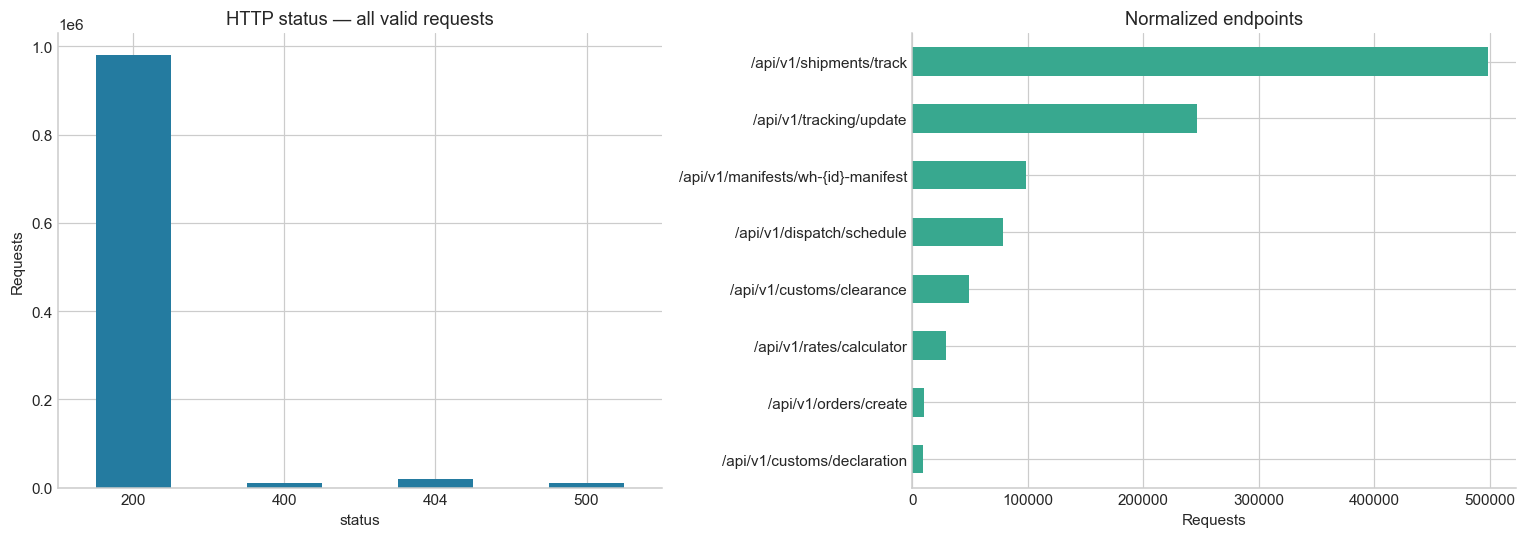

In [6]:
def url_features(url):
    parsed = urlsplit(url)
    endpoint = re.sub(r'/wh-\d+-manifest$', '/wh-{id}-manifest', parsed.path)
    query = parse_qs(parsed.query)
    tx = query.get('tx_id', [None])[0]
    return endpoint, tx, query.get('order_id', [None])[0], query.get('entry_no', [None])[0]

url_map = {u: url_features(u) for u in df.url.unique()}
for i, column in enumerate(['endpoint', 'tx_id', 'order_id', 'entry_no']):
    df[column] = df.url.map({u: v[i] for u, v in url_map.items()})
df['endpoint'] = df.endpoint.astype('category')
df['status_class'] = (df.status.astype(int) // 100).astype(str) + 'xx'
df['http_error'] = df.status >= 400

status_summary = df.groupby('status', observed=True).agg(requests=('status', 'size'))
status_summary['share_pct'] = status_summary.requests / len(df) * 100
endpoint_summary = df.groupby(['method', 'endpoint'], observed=True).agg(
    requests=('status', 'size'), error_rate=('http_error', 'mean'),
    median_ms=('latency_ms', 'median'), p95_ms=('latency_ms', lambda s: s.quantile(.95)),
    total_bytes=('response_bytes', 'sum')).sort_values('requests', ascending=False)
endpoint_summary['share_pct'] = endpoint_summary.requests / len(df) * 100
display(status_summary)
display(endpoint_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
status_summary.requests.plot.bar(ax=axes[0], color='#247BA0', rot=0)
axes[0].set(title='HTTP status — all valid requests', ylabel='Requests')
df.endpoint.value_counts().sort_values().plot.barh(ax=axes[1], color='#38A88F')
axes[1].set(title='Normalized endpoints', xlabel='Requests', ylabel='')
fig.tight_layout()
fig.savefig(OUT / 'http_endpoints.png', bbox_inches='tight')
plt.show()

HTTP **200 có 981.101 request, chiếm 96,14%**. Phần còn lại gồm **9.680 request HTTP 400**, **19.853 request HTTP 404** và **9.861 request HTTP 500**, tổng cộng khoảng **3,86%** request hợp lệ. Đây là phản hồi HTTP lỗi, khác với entry sai định dạng không đọc được.

API theo dõi vận đơn chiếm **48,82%**, tiếp theo là cập nhật tracking với **24,16%**; hai nhóm này cộng lại chiếm khoảng **72,98%**. Việc chuẩn hóa URL giúp gom các request có mã giao dịch khác nhau về cùng loại API để nhìn rõ phân bố.

Hai endpoint tạo đơn và khai báo hải quan có tỷ lệ HTTP error **100%** vì generator cố định status 500 và 400 cho chúng. Đây là kịch bản mô phỏng, không phải bằng chứng hai dịch vụ thực đang hỏng. Trong bảng, `error_rate = 1` nghĩa là 100%, còn `0.04` tương đương khoảng 4%.

## Cell 7 — Phân tích quốc gia và IP

Thống kê request theo quốc gia/IP; tính riêng HTTP 200 và top 10 làm số liệu tham chiếu cho Task 1.

Top 10 IP share: 0.32%
Country max / median count: 2.00


,requests,unique_ips,error_rate,p95_ms,http_200,share_pct
country,,,,,,
United States,136207,498,0.039,191.000,130916,13.347
Vietnam,68440,249,0.039,191.000,65769,6.707
Singapore,68278,249,0.038,191.000,65698,6.691
Australia,68242,249,0.039,191.000,65585,6.687
Netherlands,68209,249,0.039,191.000,65570,6.684
Germany,68059,249,0.039,191.000,65410,6.669
Sweden,68049,249,0.039,191.000,65371,6.668
India,68030,249,0.039,190.000,65402,6.666
South Korea,67979,249,0.038,191.000,65382,6.661


,access_count
country,
United States,130916
Vietnam,65769
Singapore,65698
Australia,65585
Netherlands,65570
Germany,65410
India,65402
South Korea,65382
Sweden,65371


,requests,country,error_rate
ip,,,
200.160.0.161,330,Brazil,0.033
103.7.32.9,329,Singapore,0.024
194.67.192.33,328,Sweden,0.030
203.0.112.47,327,Japan,0.034
198.51.100.243,327,United States,0.046
194.67.192.154,325,Sweden,0.055
145.220.0.133,324,Netherlands,0.043
139.130.0.13,324,Australia,0.034
185.220.96.19,323,Germany,0.019


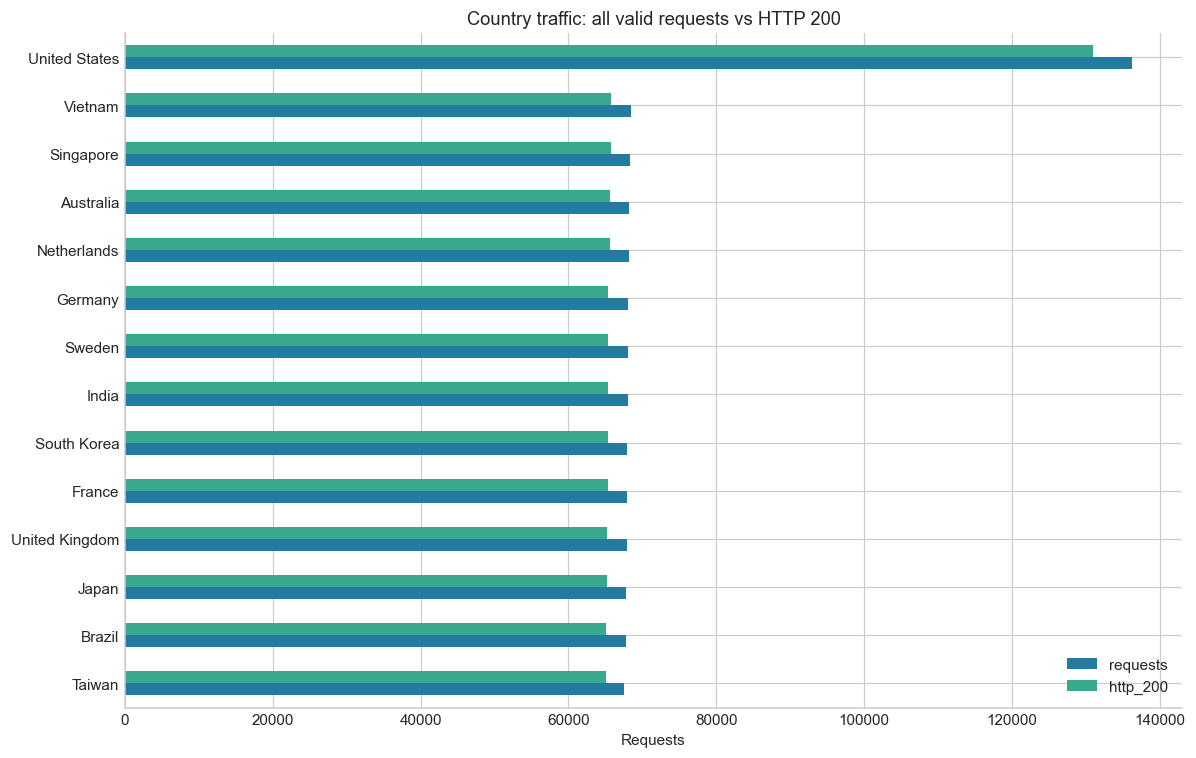

In [7]:
country_summary = df.groupby('country', observed=True).agg(
    requests=('status', 'size'), unique_ips=('ip', 'nunique'),
    error_rate=('http_error', 'mean'), p95_ms=('latency_ms', lambda s: s.quantile(.95)))
success_counts = df.loc[df.status == 200].groupby('country', observed=True).size()
country_summary['http_200'] = success_counts.reindex(country_summary.index, fill_value=0)
country_summary['share_pct'] = country_summary.requests / len(df) * 100
country_summary = country_summary.sort_values('requests', ascending=False)
top10_task1 = country_summary[['http_200']].sort_values('http_200', ascending=False).head(10)
display(country_summary)
display(top10_task1.rename(columns={'http_200': 'access_count'}))
ip_summary = df.groupby('ip', observed=True).agg(requests=('status', 'size'),
    country=('country', 'first'), error_rate=('http_error', 'mean')).sort_values('requests', ascending=False)
display(ip_summary.head(15))
print(f'Top 10 IP share: {ip_summary.requests.head(10).sum() / len(df):.2%}')
print(f'Country max / median count: {country_summary.requests.max() / country_summary.requests.median():.2f}')
ax = country_summary[['requests', 'http_200']].sort_values('requests').plot.barh(figsize=(11, 7), color=['#247BA0', '#38A88F'])
ax.set(title='Country traffic: all valid requests vs HTTP 200', xlabel='Requests', ylabel='')
plt.tight_layout()
plt.savefig(OUT / 'country_traffic.png', bbox_inches='tight')
plt.show()

US có **136.207 request (13,35%)**, cao nhất; Việt Nam có **68.440 request**, tiếp theo là Singapore với **68.278**. Các quốc gia ngoài US đều có lượng request khá gần nhau. US cao gần gấp đôi mức trung vị vì có hai dải IP trong generator, không phải bằng chứng về nhu cầu thị trường.

Khi chỉ tính HTTP 200 để đối chiếu Task 1, US còn **130.916 lượt**, Việt Nam **65.769 lượt**. Hai cột trên biểu đồ giúp phân biệt tổng request hợp lệ với phần được pipeline giữ lại sau điều kiện status 200.

Top 10 IP chỉ đóng góp **0,32%** request; IP nhiều nhất có **330 request**. Dữ liệu không tập trung mạnh vào một vài IP. Tuy nhiên, phân bố theo IP/quốc gia chưa cho biết Spark partitions có bị skew hay không; việc đó cần quan sát khi chạy Spark.

## Cell 8 — Phân tích độ trễ và kích thước phản hồi

Tính trung bình, phân vị, giá trị ngoài ngưỡng IQR và tương quan bytes–latency. Chỉ biểu đồ scatter lấy mẫu 10.000 request; thống kê dùng toàn bộ dữ liệu hợp lệ.

Pearson correlation (full data): 0.07408721399241702


,count,mean,std,min,50%,90%,95%,99%,max
response_bytes,"1,020,495.000","2,057.776","1,163.766",128.000,"2,040.000","3,687.000","3,892.000","4,055.000","4,096.000"
latency_ms,"1,020,495.000",101.889,56.611,10.000,102.000,181.000,191.000,199.000,200.000


,field,lower,upper,flagged,flagged_pct
0,response_bytes,"-2,074.000","6,158.000",0,0.000
1,latency_ms,-96.500,299.500,0,0.000


,requests,median_ms,p95_ms,p99_ms
status,,,,
200,981101,101.000,191.000,199.000
400,9680,103.000,191.000,199.000
404,19853,105.000,191.000,199.000
500,9861,105.000,191.000,199.000


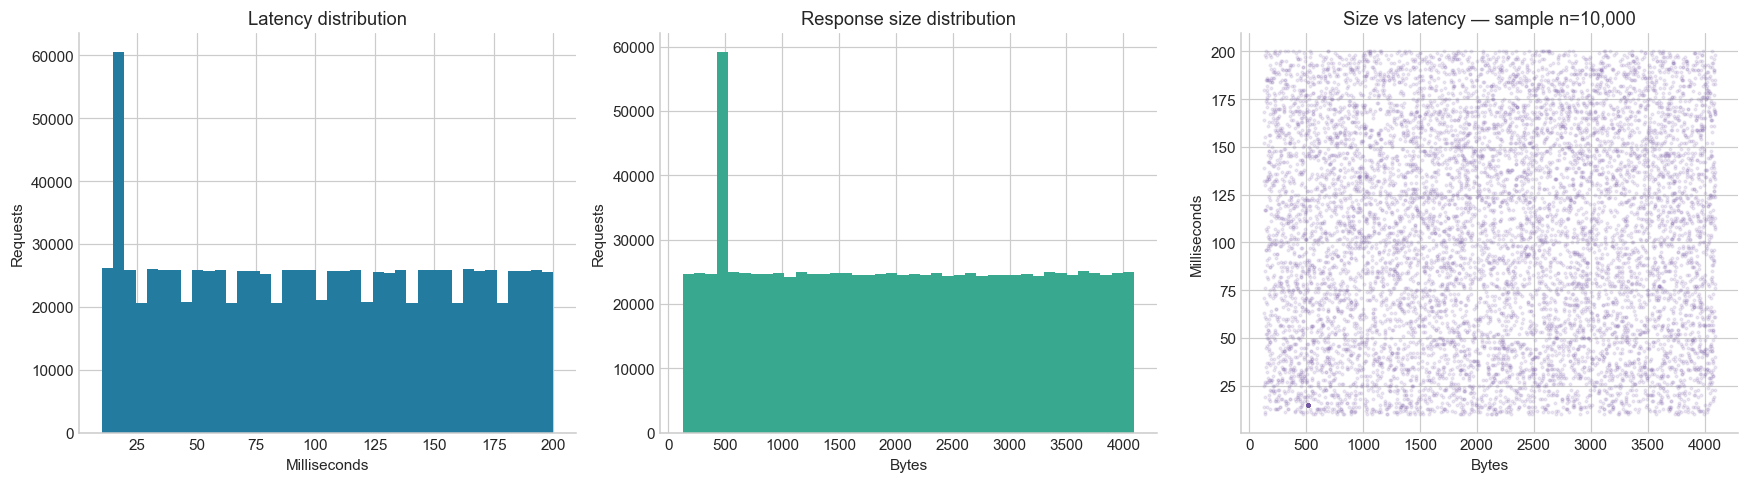

In [8]:
numeric_summary = df[['response_bytes', 'latency_ms']].describe(percentiles=[.5, .9, .95, .99]).T
display(numeric_summary)
outlier_rows = []
for c in ['response_bytes', 'latency_ms']:
    q1, q3 = df[c].quantile([.25, .75])
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = (df[c] < lo) | (df[c] > hi)
    outlier_rows.append({'field': c, 'lower': lo, 'upper': hi,
                         'flagged': int(flagged.sum()), 'flagged_pct': flagged.mean() * 100})
outliers = pd.DataFrame(outlier_rows)
display(outliers)
display(df.groupby('status').agg(requests=('status', 'size'), median_ms=('latency_ms', 'median'),
    p95_ms=('latency_ms', lambda s: s.quantile(.95)), p99_ms=('latency_ms', lambda s: s.quantile(.99))))
print('Pearson correlation (full data):', df.response_bytes.corr(df.latency_ms))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].hist(df.latency_ms, bins=40, color='#247BA0')
axes[0].set(title='Latency distribution', xlabel='Milliseconds', ylabel='Requests')
axes[1].hist(df.response_bytes, bins=40, color='#38A88F')
axes[1].set(title='Response size distribution', xlabel='Bytes', ylabel='Requests')
sample = df.sample(n=min(10000, len(df)), random_state=SEED)
axes[2].scatter(sample.response_bytes, sample.latency_ms, s=3, alpha=.12, color='#7659A5')
axes[2].set(title=f'Size vs latency — sample n={len(sample):,}', xlabel='Bytes', ylabel='Milliseconds')
fig.tight_layout()
fig.savefig(OUT / 'latency_size.png', bbox_inches='tight')
plt.show()

Latency nằm trong khoảng **10–200 ms**, trung bình **101,89 ms** và trung vị **102 ms**. Các phân vị p95 **191 ms**, p99 **199 ms** có nghĩa khoảng 95% và 99% request không vượt quá các ngưỡng tương ứng. Kích thước phản hồi nằm trong khoảng **128–4.096 bytes**, trung bình **2.057,78 bytes**.

Không có điểm nào nằm ngoài ngưỡng IQR ở hai cột. Kết quả này hợp lý với dữ liệu được sinh trong khoảng giới hạn; không có outlier theo IQR không đồng nghĩa hệ thống đạt SLA. Các nhóm HTTP status có p95/p99 giống nhau (**191/199 ms**), nên không thấy khác biệt lớn ở các phân vị này.

Tương quan Pearson bytes–latency chỉ khoảng **0,074**, cho thấy quan hệ tuyến tính rất yếu. Biểu đồ có phần tập trung quanh **512 bytes và 15 ms**, liên quan đến request thứ hai được sinh cố định. Các thống kê dùng toàn bộ request hợp lệ; riêng scatter dùng mẫu 10.000 request để dễ nhìn.

## Cell 9 — Kiểm tra đặc điểm dữ liệu giả lập

So sánh request thứ nhất/thứ hai, kiểm tra timestamp và mức xuất hiện các mã giao dịch trong URL.

In [9]:
position_summary = df.groupby('entry_position').agg(requests=('status', 'size'),
    success_rate=('status', lambda s: (s == 200).mean()),
    median_bytes=('response_bytes', 'median'), median_ms=('latency_ms', 'median'),
    distinct_latency=('latency_ms', 'nunique'))
display(position_summary)
print('Timestamp range:', df.timestamp.min(), '→', df.timestamp.max())
print('Unique timestamps:', df.timestamp.nunique())
if df.timestamp.nunique() <= 1:
    display(Markdown('**Không vẽ time series:** dữ liệu chỉ có một timestamp; không đủ cơ sở phân tích xu hướng.'))
else:
    df.set_index('timestamp').resample('h').size().plot(title='Requests by hour (observed timestamps)', ylabel='Requests')
    plt.tight_layout()
    plt.show()
metadata_summary = pd.DataFrame([{'field': c, 'present': df[c].notna().sum(),
    'coverage_pct': df[c].notna().mean() * 100, 'unique_values': df[c].nunique()}
    for c in ['tx_id', 'order_id', 'entry_no']])
display(metadata_summary)
print('TX IDs starting with INVALID:', df.tx_id.str.startswith('INVALID-', na=False).sum())

Timestamp range: 2026-09-16 10:00:00+00:00 → 2026-09-16 10:00:00+00:00
Unique timestamps: 1
TX IDs starting with INVALID: 19853


,requests,success_rate,median_bytes,median_ms,distinct_latency
entry_position,,,,,
1,986092,0.960,"2,110.000",105.000,191
2,34403,1.000,512.000,15.000,1


**Không vẽ time series:** dữ liệu chỉ có một timestamp; không đủ cơ sở phân tích xu hướng.

,field,present,coverage_pct,unique_values
0,tx_id,744789,72.983,107842
1,order_id,78847,7.726,52470
2,entry_no,49145,4.816,37921


Có **986.092 request hợp lệ ở vị trí thứ nhất** và **34.403 request ở vị trí thứ hai**. Request thứ hai đều trả HTTP 200, có kích thước **512 bytes** và độ trễ **15 ms**; đây là quy tắc cố định của generator. Nhóm này góp phần tạo đỉnh trên histogram và kéo các thống kê latency/bytes chung xuống so với nhóm đầu.

Toàn bộ request có cùng timestamp **16/09/2026 lúc 10:00 UTC**, nên không đủ cơ sở phân tích giờ cao điểm, xu hướng hoặc throughput thực tế. Notebook không vẽ time series để tránh tạo cảm giác có biến động theo thời gian.

`tx_id` có mặt ở **72,98%** request, `order_id` ở **7,73%**, `entry_no` ở **4,82%**. Mỗi loại endpoint dùng tham số khác nhau nên không có tham số không mặc nhiên là lỗi. Có **19.853 mã bắt đầu bằng INVALID-**, bằng số request HTTP 404 trong snapshot và phù hợp với kịch bản sinh dữ liệu.

## Cell 10 — Đối soát và tổng hợp kết quả

Kiểm tra các tổng đếm có nhất quán không, đối chiếu hai parser và tạo kết luận từ số liệu EDA. Không chạy kiểm thử phục hồi lỗi của Spark.

In [10]:
checks = pd.Series({
    'Expanded entries = valid + invalid': audit['entries'] == len(df) + invalid_entries,
    'All valid requests covered by country summary': country_summary.requests.sum() == len(df),
    'HTTP status counts conserved': status_summary.requests.sum() == len(df),
    'Task regex accepted count equals strict parser': audit['task_regex_valid'] == len(df),
    'Task HTTP 200 count equals EDA': audit['task_status_200'] == int((df.status == 200).sum()),
    'Nonnegative latency and bytes': bool((df[['latency_ms', 'response_bytes']] >= 0).all().all())
}, name='passed')
display(checks.to_frame())
assert checks.all(), 'Có kiểm tra không đạt: xem dữ liệu/parser trước khi đối soát Task 1.'

findings = f"""### Kết quả trên snapshot hiện tại
- **{audit['physical_lines']:,} dòng vật lý**, trong đó **{audit['compound_lines']:,} dòng ghép**.
- Sau tách: **{audit['entries']:,} entries**, gồm **{len(df):,} request hợp lệ** và **{invalid_entries:,} entry lỗi**.
- Tỷ lệ dòng chứa lỗi: **{audit['lines_with_invalid_entries'] / audit['physical_lines']:.2%}**; tỷ lệ HTTP 4xx/5xx trên request hợp lệ: **{df.http_error.mean():.2%}**.
- Task 1 giữ **{(df.status == 200).sum():,} request HTTP 200** trước khi tổng hợp quốc gia.
- Có **{df.ip.nunique():,} IP**, **{df.country.nunique():,} nhóm quốc gia**; **{(df.country == 'Unknown').sum():,} request Unknown**.
- Quốc gia có nhiều request nhất: **{country_summary.index[0]}**, chiếm **{country_summary.share_pct.iloc[0]:.2f}%** request hợp lệ.
- Latency p50/p95/p99: **{df.latency_ms.quantile(.5):.0f}/{df.latency_ms.quantile(.95):.0f}/{df.latency_ms.quantile(.99):.0f} ms**.
- Có **{df.timestamp.nunique():,} timestamp phân biệt**, **{duplicates:,} bản ghi trùng ngoài lần xuất hiện đầu tiên**.

### Diễn giải và giới hạn
- Dataset phù hợp minh họa parsing, flatMap, lọc HTTP 200, Accumulator và broadcast lookup.
- Tỷ lệ lỗi định dạng và request ghép được chủ động sinh ra; không phải bằng chứng về chất lượng dịch vụ thực.
- Phân bố địa lý chịu ảnh hưởng số CIDR mỗi quốc gia; request thứ hai có bytes/latency cố định.
- Không suy luận SLA, hành vi khách hàng hoặc vị trí IP thực tế từ dữ liệu mô phỏng này.
- EDA dùng parser đầy đủ, còn Task 1 dùng regex tiền tố. Với nguồn khác, hai parser có thể chấp nhận số record khác nhau.
"""
display(Markdown(findings))

,passed
Expanded entries = valid + invalid,True
All valid requests covered by country summary,True
HTTP status counts conserved,True
Task regex accepted count equals strict parser,True
Task HTTP 200 count equals EDA,True
Nonnegative latency and bytes,True


### Kết quả trên snapshot hiện tại
- **1,000,000 dòng vật lý**, trong đó **34,403 dòng ghép**.
- Sau tách: **1,034,403 entries**, gồm **1,020,495 request hợp lệ** và **13,908 entry lỗi**.
- Tỷ lệ dòng chứa lỗi: **1.39%**; tỷ lệ HTTP 4xx/5xx trên request hợp lệ: **3.86%**.
- Task 1 giữ **981,101 request HTTP 200** trước khi tổng hợp quốc gia.
- Có **3,735 IP**, **14 nhóm quốc gia**; **0 request Unknown**.
- Quốc gia có nhiều request nhất: **United States**, chiếm **13.35%** request hợp lệ.
- Latency p50/p95/p99: **102/191/199 ms**.
- Có **1 timestamp phân biệt**, **3 bản ghi trùng ngoài lần xuất hiện đầu tiên**.

### Diễn giải và giới hạn
- Dataset phù hợp minh họa parsing, flatMap, lọc HTTP 200, Accumulator và broadcast lookup.
- Tỷ lệ lỗi định dạng và request ghép được chủ động sinh ra; không phải bằng chứng về chất lượng dịch vụ thực.
- Phân bố địa lý chịu ảnh hưởng số CIDR mỗi quốc gia; request thứ hai có bytes/latency cố định.
- Không suy luận SLA, hành vi khách hàng hoặc vị trí IP thực tế từ dữ liệu mô phỏng này.
- EDA dùng parser đầy đủ, còn Task 1 dùng regex tiền tố. Với nguồn khác, hai parser có thể chấp nhận số record khác nhau.


Cả **6 kiểm tra đều đạt**: tổng entry bằng hợp lệ cộng lỗi; các tổng theo quốc gia và HTTP status khớp tổng request hợp lệ; số lượng hai parser chấp nhận và số HTTP 200 khớp nhau; bytes và latency không âm. Những kiểm tra này giúp phát hiện sai lệch trong quá trình đọc và tổng hợp EDA.

Dataset có đủ các tình huống để minh họa Task 1: request ghép để tách, log hỏng để đếm, HTTP status để lọc và bảng IP–quốc gia để tra cứu. Tuy nhiên, timestamp cố định và các phân bố do generator thiết kế giới hạn khả năng suy luận về hoạt động logistics thực tế.

EDA giữ nguyên file nguồn, bao gồm các dòng lỗi. Các kết quả trên xác nhận sự nhất quán của phân tích, **chưa kiểm chứng khả năng Spark phục hồi khi task/executor gặp sự cố hoặc hành vi Accumulator khi chạy lại**.